<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Bureau of Economic Analysis](https://github.com/Query-farm/vgi-bea)

Discover BEA datasets, parameters and parameter values, then retrieve national, regional, industry and international economic accounts.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-bea/blob/main/notebooks/02_discovery_and_complete_pairs.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-bea/blob/main/notebooks/README.md)

## A row cap can break the denominator pair

How do we discover the parameters for an income comparison, and verify that a bounded result still contains both income and population for each region? We build a request from discovered metadata, then compare a complete eight-row response with a deliberately capped result.

**Every dataset entry, geography, value and note here is synthetic.** The real released BEA worker reads a strict local HTTP fixture. The exercise is about query construction, row grain and missing data, not actual regional performance or a current BEA catalog snapshot.

### Choose a deliberately small result cap

`ROW_CAP` is 3 or 5. The full reference always contains eight rows: income and population for four invented regions. Change 3 to 5 at the end. This cap limits what the worker emits **after** it receives the response; it does not change the upstream request or guarantee complete geography pairs.

In [1]:
ROW_CAP = 3  # Experiment: 5

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.30":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.30"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
if type(ROW_CAP) is not int or ROW_CAP not in (3, 5):
    raise ValueError("ROW_CAP must be the integer 3 or 5.")

from vgi_notebooks import check_runtime, connect, finish, prepare, prose, theme

check_runtime()
prepare("bea")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from IPython.display import display  # noqa: E402

from bea_fixture import SyntheticBEA  # noqa: E402

theme()
fixture = SyntheticBEA()
session = connect(globals())
SOURCE = "Invented BEA-shaped observations and discovery metadata · local fixture · vgi-bea v0.1.1"
COLORS = {"Aster": "#2b8067", "Briar": "#4a6f9b", "Cedar": "#c27548", "Dune": "#8b9690"}

### Connect the released worker

Haybarn runs BEA **v0.1.1** in an isolated worker environment. The companion directs its supported endpoint override to a local synthetic server. The all-zero GUID is an intentionally invalid public test key; the fixture rejects every other key. No request goes to BEA. A live request requires your own BEA key and the normal public endpoint; the example's invented dataset and caps are not evidence about current BEA service contents.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'bea' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-bea@v0.1.1 vgi-bea-worker'
);
CREATE TEMPORARY SECRET synthetic_bea (
    TYPE bea_api, API_KEY '00000000-0000-0000-0000-000000000000'
);

,Success


### Select the account, then inspect its request contract

`datasets()` supplies dataset identifiers. Select the Regional entry and materialize its parameter metadata. The plan below specifies all four required fields. The metadata join checks required-field coverage and whether the comma-separated line selector is allowed; a description match alone would not validate the request.

In [5]:
%%sql
CREATE TABLE discovered_datasets AS SELECT * FROM bea.main.datasets();
CREATE TABLE request_contract AS SELECT * FROM bea.main.parameters('Regional');
CREATE TABLE request_plan (parameter_name VARCHAR, supplied_value VARCHAR);
INSERT INTO request_plan VALUES
 ('TableName', 'SAINC1'), ('LineCode', '1,2'), ('GeoFIPS', 'STATE'), ('Year', '2024');

,Count


In [6]:
%%sql contract <<
SELECT p.parameter_name, p.description, p.is_required, p.multiple_accepted,
       q.supplied_value,
       q.supplied_value IS NOT NULL AS supplied,
       NOT contains(coalesce(q.supplied_value, ''), ',') OR p.multiple_accepted AS cardinality_allowed
FROM request_contract p LEFT JOIN request_plan q USING (parameter_name)
ORDER BY p.parameter_name;

In [7]:
display(session.connection.execute("SELECT * FROM discovered_datasets ORDER BY dataset_name").df())
display(contract)
assert len(contract) == 4 and contract.supplied.all() and contract.cardinality_allowed.all()
prose(
    "All four required fields are supplied. LineCode accepts the two-value selector. These flags validate the constructed fixture request; the selected table still needs its own measure metadata."
)

,dataset_name,description
0,NIPA,Synthetic national-account discovery entry
1,Regional,Synthetic regional income and population


,parameter_name,description,is_required,multiple_accepted,supplied_value,supplied,cardinality_allowed
0,GeoFIPS,Geography selector,True,True,STATE,True,True
1,LineCode,Measure identifier within the selected table,True,True,"1,2",True,True
2,TableName,Table identifier,True,False,SAINC1,True,True
3,Year,"Observation period, not release vintage",True,True,2024,True,True


All four required fields are supplied. LineCode accepts the two-value selector. These flags validate the constructed fixture request; the selected table still needs its own measure metadata.

### Resolve the table and its measure keys

Discover `TableName` without filters, then discover `LineCode` **within SAINC1**. Nonempty `filters_json` selects BEA's filtered discovery method, which is supported only for some datasets. Use the returned keys to verify the explicit plan before retrieving observations. Keep the descriptions: line 1 is an income numerator; line 2 is a population denominator.

In [8]:
%%sql
CREATE TABLE table_options AS SELECT * FROM bea.main.parameter_values('Regional', 'TableName');
CREATE TABLE line_options AS SELECT * FROM bea.main.parameter_values(
 'Regional', 'LineCode', filters_json := '{"TableName":"SAINC1"}'
);
CREATE TABLE selected_lines AS
SELECT l.key, l.description FROM line_options l
JOIN unnest(string_split((SELECT supplied_value FROM request_plan WHERE parameter_name='LineCode'), ',')) s(key)
 USING (key);

,Count


In [9]:
display(session.connection.execute("SELECT key, description FROM table_options ORDER BY key").df())
display(session.connection.execute("SELECT key, description FROM selected_lines ORDER BY key").df())
assert session.connection.execute("SELECT count(*) FROM table_options WHERE key='SAINC1'").fetchone()[0] == 1
assert session.connection.execute("SELECT count(*) FROM selected_lines").fetchone()[0] == 2
prose(
    "SAINC1 resolves to the invented income/population table, with both requested measure keys present. The next calls use exactly those explicit selectors; discovery has not fetched observations yet."
)

,key,description
0,SAINC1,Synthetic personal income and population


,key,description
0,1,Personal income
1,2,Population


SAINC1 resolves to the invented income/population table, with both requested measure keys present. The next calls use exactly those explicit selectors; discovery has not fetched observations yet.

### Compare complete and capped results from the same request

Materialize both calls once. The reference cap of 100 exceeds the fixture's eight rows; the experiment cap deliberately does not. `notes()` makes a separate request with the same parameters and preserves the suppression explanation. In a real service, independently acquired data and notes may change between requests; a reproducible acquisition should retain both with its timestamp and provenance.

In [10]:
%%sql
CREATE TABLE complete AS SELECT * FROM bea.main.data('Regional',
 '{"TableName":"SAINC1","LineCode":"1,2","GeoFIPS":"STATE","Year":"2024"}', max_rows := 100);
CREATE TABLE capped AS SELECT * FROM bea.main.data('Regional',
 '{"TableName":"SAINC1","LineCode":"1,2","GeoFIPS":"STATE","Year":"2024"}', max_rows := {{ROW_CAP}});
CREATE TABLE source_notes AS SELECT * FROM bea.main.notes('Regional',
 '{"TableName":"SAINC1","LineCode":"1,2","GeoFIPS":"STATE","Year":"2024"}');

,Count


In [11]:
%%sql notes <<
SELECT d.geo_name, d.line_description, d.value_text, d.value, n.note_text
FROM complete d LEFT JOIN source_notes n
 ON list_contains(string_split(d.note_ref, ','), n.note_ref)
WHERE d.value IS NULL ORDER BY d.geo_fips, d.line_number;

In [12]:
display(notes)
prose(
    "Dune's income row is present but suppressed: its original '(D)' remains alongside a NULL numeric value and the qualifying note. Rows absent from the capped result are a different form of unavailability. Neither should become a zero."
)

,geo_name,line_description,value_text,value,note_text
0,Dune,Personal income,(D),NaN,Entire response is synthetic. (D) marks a deli...


Dune's income row is present but suppressed: its original '(D)' remains alongside a NULL numeric value and the qualifying note. Rows absent from the capped result are a different form of unavailability. Neither should become a zero.

### Keep every reference region visible when counting complete pairs

Start from the complete reference geography set, left join the capped rows, and count both row presence and numeric availability. The presence check requires two distinct measure lines at the same geography and observation period. A complete pair can still contain a suppressed income, so we report presence and calculability separately.

In [13]:
%%sql pairs <<
WITH expected AS (
 SELECT time_period, geo_fips, geo_name, count(*) AS expected_rows
 FROM complete GROUP BY ALL
), received AS (
 SELECT time_period, geo_fips, count(*) AS emitted_rows,
        count(DISTINCT line_number) AS emitted_lines,
        max(value * power(10, unit_multiplier)) FILTER (WHERE line_number='1') AS income_usd,
        max(value * power(10, unit_multiplier)) FILTER (WHERE line_number='2') AS population
 FROM capped GROUP BY ALL
)
SELECT e.*, coalesce(r.emitted_rows, 0) AS emitted_rows,
       coalesce(r.emitted_lines, 0)=2 AS both_lines_present,
       CASE WHEN r.population > 0 THEN r.income_usd / r.population END AS income_per_person_usd
FROM expected e LEFT JOIN received r USING (time_period, geo_fips)
ORDER BY e.geo_fips;

,time_period,geo_fips,geo_name,expected_rows,emitted_rows,both_lines_present,income_per_person_usd
0,2024,00001,Aster,2,2,True,60000.0
1,2024,00002,Briar,2,1,False,NaN
2,2024,00003,Cedar,2,0,False,NaN
3,2024,00004,Dune,2,0,False,NaN


With a cap of **3**, **1 of 4 reference regions** retain both rows, and **1** have a calculable ratio. The ordering is an authored fixture property, not a promise that a live cap chooses a stable or representative sample.

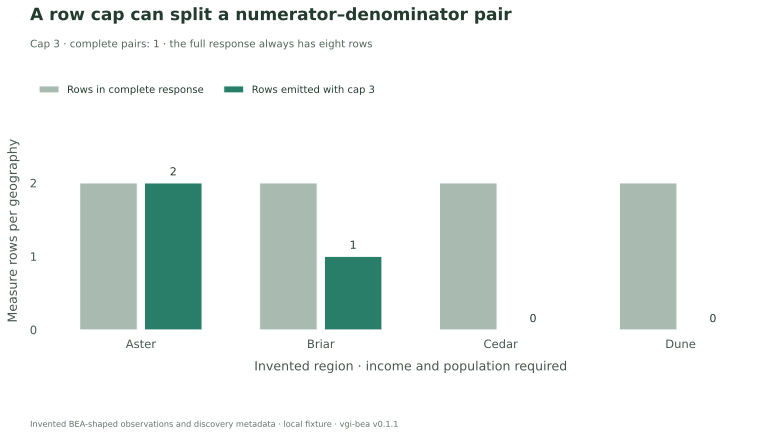

In [14]:
display(pairs)
prose(
    f"With a cap of **{ROW_CAP}**, **{int(pairs.both_lines_present.sum())} of {len(pairs)} reference regions** retain both rows, and **{int(pairs.income_per_person_usd.notna().sum())}** have a calculable ratio. The ordering is an authored fixture property, not a promise that a live cap chooses a stable or representative sample."
)
fig, ax = plt.subplots(figsize=(11.5, 6.4))
x = np.arange(len(pairs))
ax.bar(x - 0.18, pairs.expected_rows, width=0.32, color="#A9BAB1", label="Rows in complete response")
bars = ax.bar(x + 0.18, pairs.emitted_rows, width=0.32, color="#287E69", label=f"Rows emitted with cap {ROW_CAP}")
ax.bar_label(bars, padding=5)
ax.set(
    xticks=x,
    xticklabels=pairs.geo_name,
    yticks=[0, 1, 2],
    ylim=(0, 2.7),
    ylabel="Measure rows per geography",
    xlabel="Invented region · income and population required",
)
fig.legend(*ax.get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.07, 0.82), ncol=2, fontsize=10)
finish(
    fig,
    "A row cap can split a numerator–denominator pair",
    f"Cap {ROW_CAP} · complete pairs: {int(pairs.both_lines_present.sum())} · the full response always has eight rows",
    SOURCE,
    name=f"pairs-cap-{ROW_CAP}",
)

### Reconcile local results with the transport audit

The fixture records method names, noncredential selectors and returned row counts. Three GetData requests serve eight rows each: complete data, capped data and notes. A downstream cap does not reduce those response sizes. The SQL checks also require unique reference keys, unchanged overlapping rows and a single resolvable note per suppressed row.

In [15]:
%%sql checks <<
SELECT 'two datasets and selected Regional account' AS check_name,
 (SELECT count(*)=2 AND count(*) FILTER(WHERE dataset_name='Regional')=1 FROM discovered_datasets) AS passed
UNION ALL SELECT 'all required parameters supplied', (SELECT count(*)=0 FROM request_contract c LEFT JOIN request_plan p USING(parameter_name) WHERE c.is_required AND p.supplied_value IS NULL)
UNION ALL SELECT 'both discovered measure keys selected', (SELECT list(key ORDER BY key)=['1','2'] FROM selected_lines)
UNION ALL SELECT 'complete eight unique measure rows', (SELECT count(*)=8 AND count(DISTINCT (geo_fips,time_period,line_number))=8 FROM complete)
UNION ALL SELECT 'cap limits emitted rows', (SELECT count(*)={{ROW_CAP}} FROM capped)
UNION ALL SELECT 'every capped value matches reference', (SELECT count(*)=0 FROM (SELECT * FROM capped EXCEPT SELECT * FROM complete))
UNION ALL SELECT 'one suppression note remains resolvable', (SELECT count(*)=1 FROM complete d JOIN source_notes n ON d.note_ref=n.note_ref WHERE d.value IS NULL AND d.value_text='(D)' AND n.note_text LIKE '%not zero%')
UNION ALL SELECT 'retained pairs match selected cap', (SELECT count(*)=({{ROW_CAP}} // 2) FROM (SELECT geo_fips FROM capped GROUP BY geo_fips HAVING count(DISTINCT line_number)=2))
ORDER BY check_name;

In [16]:
display(checks)
assert len(checks) == 8 and checks.passed.notna().all() and checks.passed.all()
methods = [r["method"] for r in fixture.requests]
assert methods == [
    "GetDatasetList",
    "GetParameterList",
    "GetParameterValues",
    "GetParameterValuesFiltered",
    "GetData",
    "GetData",
    "GetData",
]
assert [r["response_rows"] for r in fixture.requests[-3:]] == [8, 8, 8]
assert all(r["public_test_key_only"] for r in fixture.requests)
display(pd.DataFrame(fixture.requests))
prose(
    "All eight SQL checks pass. The full eight-row body was served for every data/notes request. Narrowing explicit upstream selectors is the way to bound acquisition; a post-response row cap alone cannot do that."
)

,check_name,passed
0,all required parameters supplied,True
1,both discovered measure keys selected,True
2,cap limits emitted rows,True
3,complete eight unique measure rows,True
4,every capped value matches reference,True
5,one suppression note remains resolvable,True
6,retained pairs match selected cap,True
7,two datasets and selected Regional account,True


,method,parameters,response_rows,public_test_key_only
0,GetDatasetList,{'method': 'GetDatasetList'},2,True
1,GetParameterList,"{'datasetname': 'Regional', 'method': 'GetPara...",4,True
2,GetParameterValues,"{'datasetname': 'Regional', 'parametername': '...",1,True
3,GetParameterValuesFiltered,"{'tablename': 'SAINC1', 'datasetname': 'Region...",2,True
4,GetData,"{'tablename': 'SAINC1', 'linecode': '1,2', 'ge...",8,True
5,GetData,"{'tablename': 'SAINC1', 'linecode': '1,2', 'ge...",8,True
6,GetData,"{'tablename': 'SAINC1', 'linecode': '1,2', 'ge...",8,True


All eight SQL checks pass. The full eight-row body was served for every data/notes request. Narrowing explicit upstream selectors is the way to bound acquisition; a post-response row cap alone cannot do that.

### Experiment: retain five rows instead of three

Change **`ROW_CAP = 3` to `5`**, restart and run all. Predict which region gains a complete pair and which one receives only an income row. Compare the chart, the calculated-ratio count and the request audit. The complete input, discovered metadata and suppression note must remain fixed; each GetData response must still contain eight rows. Reset to 3 for the saved default.

The missing denominator is caused by an explicit local output cap. This example does not establish a live API ordering guarantee, completeness for a large query, or an economic comparison for suppressed regions.

In [17]:
assert session.connection.execute("SELECT count(*) FROM duckdb_secrets() WHERE persistent").fetchall() == [(0,)]
session.connection.execute("DROP SECRET synthetic_bea")
session.close()
fixture.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-bea](https://github.com/Query-farm/vgi-bea)